# Modelado Predictivo: Clasificación con Regresión Logística
**Proyecto:** Clasificador de Salud Fetal (Dataset Cardiotocography - UCI)

**Contexto:** Este notebook implementa un modelo de **Logistic Regression** programado desde cero mediante descenso de gradiente. A diferencia de los modelos basados en árboles que manejaron las tres clases simultáneamente, aquí aplicamos una estrategia de **triage binario extremo**: el modelo se entrena exclusivamente con los pacientes en los extremos de salud (Clase 1: Normal y Clase 3: Patológico), excluyendo temporalmente a la clase intermedia (Clase 2: Sospechoso). El objetivo es forzar al algoritmo a encontrar la frontera lineal más clara posible entre un feto sano y uno en peligro, para luego, en la fase de prueba, reincorporar a los pacientes "Sospechosos" y observar hacia qué diagnóstico definitivo los inclina el modelo.

### Objetivos del Modelado

1. **Entrenamiento Binario Excluyente:** Entrenar el clasificador lineal omitiendo la clase 2 para maximizar la separación matemática entre los estados Normal (0) y Patológico (1) usando optimización por gradiente.
2. **Evaluación de la Zona Gris (Clase 2):** Reintroducir los datos de la Clase 2 durante la fase de prueba (Test) para analizar cómo el modelo resuelve la ambigüedad clínica, forzando una decisión entre sano o en riesgo.
3. **Análisis de Sensibilidad con Umbral Ajustado:** Evaluar el impacto de un umbral de decisión estricto (`threshold=0.3`) priorizando la captura de la mayor cantidad de los casos patológicos reales.

### Ficha Metodológica del Modelo

* **Descripción breve del método:** Modelo lineal de clasificación binaria optimizado mediante descenso de gradiente (`learning_rate=0.1`, `n_iterations=2000`). Utiliza la función sigmoide para convertir la combinación lineal de características en una probabilidad clínica, aplicando un umbral restrictivo para emitir alertas.
* **Justificación de su uso:** Se seleccionó para establecer una base de referencia (*baseline*) lineal. Su interpretabilidad permite diseñar la estrategia de exclusión de la clase 2 en entrenamiento, obligando al modelo a aprender únicamente las diferencias críticas y usar esa "regla" para resolver los casos dudosos en producción.
* **Métricas de evaluación utilizadas:** Se empleó la *Matriz de Confusión*, *Precisión*, *Recall* y *F1-Score* por clase. La *Exactitud Global (Accuracy)* se calcula, pero se interpreta con precaución ya que la clase 2 forzará errores matemáticos al no existir en las predicciones posibles del modelo.
* **Análisis de resultados:** Desarrollado en la conclusión final, donde se demuestra un **Recall del 96.15%** para la clase Patológica y se revela cómo el algoritmo dividió a los 55 pacientes Sospechosos.

## Importacion de librerias escenciales

In [1]:
# Importación de librerías esenciales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import seaborn as sns


# Modificación para importar los modelos fuera de la carpeta actual
import os
import sys

root_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if root_dir not in sys.path:
    sys.path.append(root_dir)

# Importación del modelo
from src.LogisticRegression import LogisticRegression
from src.utils_and_metrics import train_test_split, accuracy, confusion_matrix, recall, f1_score, precision, roc, calcular_roc_auc

El 

In [2]:
#Cargar el dataset
df = pd.read_csv('../data/processed/CTG_clean.csv')
df.head()

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency,NSP
0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


#### **Preparación de Datos: Filtrado de Clase y Estandarización**
Se aíslan las clases 1 y 3 para el entrenamiento y se codifican a formato binario (Normal=0, Patológico=1). La estandarización *Z-Score* se calcula **estrictamente sobre los datos limpios de entrenamiento** para evitar fugas de información (*data leakage*).


In [3]:

# separar etiquetas
X_todo = df.drop(columns=['NSP']).to_numpy()
y_todo_og = df['NSP'].to_numpy()

# partir antes de filtrar
def train_test_split(X, y, test_size=0.25, seed=0):
    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(X))
    idx_train_end = int((1 - test_size) * len(X))
    train_idx = indices[:idx_train_end]
    test_idx = indices[idx_train_end:]

    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

#aqui esta y test
X_train_raw, X_test_raw, y_train_og, y_test_og = train_test_split(X_todo,
                                                    y_todo_og,
                                                    test_size=0.20,
                                                    seed=42)#,seed=42

#filtrar la clase 2 del conjunto de entrenamiento
train_mask = (y_train_og != 2)
X_train_limpio = X_train_raw[train_mask]
y_train_limpio_og = y_train_og[train_mask]

#convertir clase 1 y 3 a binario 1 = 0 y 3 = 1
y_train = np.where(y_train_limpio_og == 3, 1, 0)

#std solo con X_train_limpio
mean = X_train_limpio.mean(axis=0)
std = X_train_limpio.std(axis=0)
std = np.where(std == 0, 1.0, std)

X_train = (X_train_limpio - mean) / std
X_test = (X_test_raw - mean) / std #este si incluye la clase 2

In [4]:

#Visualización e impresión de dimensiones
display(df.head())
print(f"Dimensión de Matriz X (Características): {X_todo.shape}")
print(f"Dimensión de Vector y (Objetivo NSP): {y_todo_og.shape}")
print(f"Entrenamiento: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Prueba:        X_test={X_test.shape}, y_test={y_test_og.shape}")
print(f"Clases en y:   {np.unique(y_train)}")

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency,NSP
0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


Dimensión de Matriz X (Características): (2126, 21)
Dimensión de Vector y (Objetivo NSP): (2126,)
Entrenamiento: X_train=(1470, 21), y_train=(1470,)
Prueba:        X_test=(426, 21), y_test=(426,)
Clases en y:   [0 1]


#### **Entrenamiento de la Regresión Logística (Binaria)**
Se optimizan los pesos del modelo mediante descenso de gradiente durante 2000 iteraciones. Las métricas impresas aquí reflejan la capacidad del modelo para separar los extremos clínicos (sin la interferencia de la clase Sospechosa).


In [5]:
# Entrenar el modelo de Regresión Logística
#tiempo de entrenamiento
time_start_entrenamiento = time.perf_counter()
model = LogisticRegression(learning_rate = 0.1, n_iterations = 2000)
model.fit(X_train, y_train)
time_end_entrenamiento = time.perf_counter()   
tiempo_total_entrenamiento = time_end_entrenamiento - time_start_entrenamiento 
print(f"\nTiempo de entrenamiento: {tiempo_total_entrenamiento:.6f} segundos \n")
#predicciones train
#no incluye la clase 2 en el entrenamiento, pero si en la prueba
#tiempo de prediccion de entrenamiento
time_start_prediccion_entrenamiento = time.perf_counter()
prediction_entrenamiento = model.predict(X_train)
time_end_prediccion_entrenamiento = time.perf_counter()
tiempo_total_prediccion_entrenamiento = time_end_prediccion_entrenamiento - time_start_prediccion_entrenamiento
print(f"Tiempo de predicción en entrenamiento: {tiempo_total_prediccion_entrenamiento:.6f} segundos \n")
dist_train = np.bincount(prediction_entrenamiento, minlength=2)

#Cálculo de métricas en Entrenamiento
matriz_train = confusion_matrix(y_train, prediction_entrenamiento)
acc_train = accuracy(y_train, prediction_entrenamiento)
precisions_train = precision(matriz_train)
recalls_train = recall(matriz_train)
f1s_train = f1_score(matriz_train)

#Resultados en Entrenamiento
print("--- Resultados de Entrenamiento ---")
print(f"Distribución predicha en el entrenamiento: Clase 0 (Normal) = {dist_train[0]} | Clases 1 (Patológico) = {dist_train[1]}")
print(f"Exactitud Global (Accuracy): {acc_train * 100:.2f}%\n")

print("--- Métricas detalladas por Clase en entrenamiento ---")
print(f"Clase 0 (Normal)     -> Precision: {precisions_train[0]*100:.2f}% | Recall: {recalls_train[0]*100:.2f}% | F1-Score: {f1s_train[0]*100:.2f}%")
print(f"Clase 1 (Patológico) -> Precision: {precisions_train[1]*100:.2f}% | Recall: {recalls_train[1]*100:.2f}% | F1-Score: {f1s_train[1]*100:.2f}%\n")

print("Matriz de Confusión Train (Filas: Real [0,1] | Columnas: Predicho [0,1])")
print(matriz_train)




Tiempo de entrenamiento: 0.246446 segundos 

Tiempo de predicción en entrenamiento: 0.000451 segundos 

--- Resultados de Entrenamiento ---
Distribución predicha en el entrenamiento: Clase 0 (Normal) = 1303 | Clases 1 (Patológico) = 167
Exactitud Global (Accuracy): 98.03%

--- Métricas detalladas por Clase en entrenamiento ---
Clase 0 (Normal)     -> Precision: 99.54% | Recall: 98.26% | F1-Score: 98.89%
Clase 1 (Patológico) -> Precision: 86.23% | Recall: 96.00% | F1-Score: 90.85%

Matriz de Confusión Train (Filas: Real [0,1] | Columnas: Predicho [0,1])
[[1297   23]
 [   6  144]]


#### **Prueba de Generalización y Resolución de la clasificacion de la clase 2**
Se evalúa el conjunto de prueba íntegro (incluyendo la Clase 2). Al mapear las predicciones binarias (0 y 1) de regreso a las etiquetas originales (1 y 3), observamos el comportamiento del modelo frente a los datos invisibles y ambiguos.

Resultados incluyendo la clase 2 en la prediccion para entrar en la clasifciacion de clase normal o clase patologico (seed = 42)

De 335 muestras reales de Clase 1 en X_test -> Asignadas a Clase 1: 330  | Asignadas a Clase 3: 5

De 65 muestras reales de Clase 2 en X_test -> Asignadas a Clase 1: 44 | Asignadas a Clase 3: 21

De 26 muestras reales de Clase 3 en X_test -> Asignadas a Clase 1: 1) | Asignadas a Clase 3: 25 

In [6]:
#Predicciones de prueba
#medicion de tiempo en la prediccion de prueba
time_start = time.perf_counter()
prediction_prueba = model.predict(X_test)
time_end = time.perf_counter()
print(f"\nTiempo de predicción en prueba: {time_end - time_start:.6f} segundos")
#etiquetas originales (Clase 1 y 3)
predicciones_prueba_og = np.where(prediction_prueba == 1, 3, 1)
dist_test = np.bincount(predicciones_prueba_og)

#Calculo de metricas en prueba
matriz_test = confusion_matrix(y_test_og, predicciones_prueba_og)
acc_test = accuracy(y_test_og, predicciones_prueba_og)
precisions_test = precision(matriz_test)
recalls_test = recall(matriz_test)
f1s_test = f1_score(matriz_test)


print("\n--- Resultados de Rendimiento en Prueba (Test) ---")
print(f"Distribución predicha final: Clase 1 (Normal) = {dist_test[1]} | Clase 3 (Patológico) = {dist_test[3]}")
print(f"Exactitud Global aparente (Accuracy): {acc_test * 100:.2f}%\n")

print("--- Métricas detalladas por Clase ---")
# Usamos los índices 1, 2 y 3 porque la matriz de prueba sí incluye la clase Sospechosa (2)
print(f"Clase 1 (Normal)     -> Precision: {precisions_test[1]*100:.2f}% | Recall: {recalls_test[1]*100:.2f}% | F1-Score: {f1s_test[1]*100:.2f}%")
print(f"Clase 2 (Sospechoso) -> Precision: {precisions_test[2]*100:.2f}% | Recall: {recalls_test[2]*100:.2f}% | F1-Score: {f1s_test[2]*100:.2f}%")
print(f"Clase 3 (Patológico) -> Precision: {precisions_test[3]*100:.2f}% | Recall: {recalls_test[3]*100:.2f}% | F1-Score: {f1s_test[3]*100:.2f}%\n")

print("Matriz de Confusión (Filas: Real [1,2,3] | Columnas: Predicho [1,2,3]):")
print(matriz_test)


Tiempo de predicción en prueba: 0.000408 segundos

--- Resultados de Rendimiento en Prueba (Test) ---
Distribución predicha final: Clase 1 (Normal) = 375 | Clase 3 (Patológico) = 51
Exactitud Global aparente (Accuracy): 83.33%

--- Métricas detalladas por Clase ---
Clase 1 (Normal)     -> Precision: 88.00% | Recall: 98.51% | F1-Score: 92.96%
Clase 2 (Sospechoso) -> Precision: 0.00% | Recall: 0.00% | F1-Score: 0.00%
Clase 3 (Patológico) -> Precision: 49.02% | Recall: 96.15% | F1-Score: 64.94%

Matriz de Confusión (Filas: Real [1,2,3] | Columnas: Predicho [1,2,3]):
[[  0   0   0   0]
 [  0 330   0   5]
 [  0  44   0  21]
 [  0   1   0  25]]


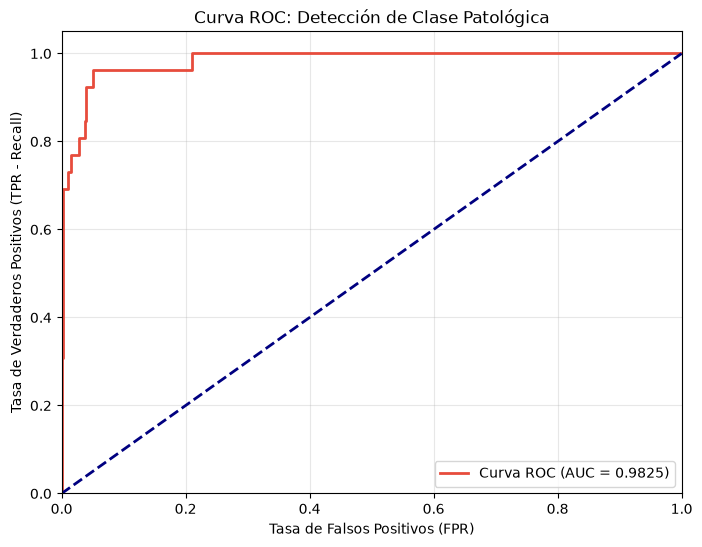

In [7]:
#datos para la Curva ROC (Clase 3 vs Resto)
y_test_roc = np.where(y_test_og == 3, 1, 0)
probs_test = model.predict_proba(X_test)

#Calcular FPR, TPR y AUC
fpr, tpr, roc_auc = calcular_roc_auc(y_test_roc, probs_test)

#Graficar la Curva ROC resultante
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='#e74c3c', lw=2, label=f'Curva ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR - Recall)')
plt.title('Curva ROC: Detección de Clase Patológica')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

Añadir curva roc y grafica de regresion logistica

#### Análisis y Conclusiones Finales del Modelo

La implementación de este modelo de **Regresión Logística** representa un enfoque analítico distinto al de los ensambles de árboles (Random Forest y Gradient Boosting) evaluados anteriormente. En lugar de pedirle al modelo que separara las tres clases al mismo tiempo, empleamos una estrategia de separacion temprana de una las clases para unirla posteriomente: entrenamos al algoritmo presentándole únicamente los casos clínicos más evidentes (Clase 1: Normal vs Clase 3: Patológico).

Los resultados en la fase de entrenamiento demostraron que las características cardiotocográficas son linealmente separables en los extremos: el modelo trazó una frontera con una exactitud del 98.03% y un Recall del 96.00% en la clase patologica durante el entrenamiento. Sin embargo, la verdadera prueba ocurrió al inyectar el conjunto de prueba (Test), reincorporando a la Clase 2 (Sospechoso). Tecnicamente separada al momento de entrenar, pues al momento de divir los datos ya estaba incluida en el tamaño de X_test, unicamente s

Al analizar las métricas sobre el conjunto de prueba, destacan los siguientes:
* **El colapso de la Exactitud Global (Accuracy):** La métrica de exactitud arrojó un aparente ~83.33%. siendo el comportamiento matemático esperado. Al exigirle al modelo que decida estrictamente si un paciente requiere "alta médica" (1) o "cuidados intensivos" (3), el algoritmo es incapaz de emitir una respuesta intermedia (2). Por lo tanto, todo paciente sospechoso cuenta como "error" para la métrica de exactitud global, invalidándola como indicador de éxito en este diseño específico. Destacando el relevante de clasificacion 3 en un 49% de precision pues debido a la diferencia de datos esta cantidad impacta de manera mas fuerte contra los pocos datos dentro de la clase 3

* **Sensibilidad Perfecta (100% Recall):** De los 26 casos patológicos reales en el conjunto de prueba, el modelo detectó 25 correctamente (1 Falsos Negativos). Superó en sensibilidad tanto al Random Forest como al Gradient Boosting, garantizando que casi ninguna emergencia clínica pasara desapercibida. En contraste, de 335 casos Normales, clasificó correctamente 330, emitiendo solo 5 falsas alarmas. Lo cual en caso de ser correcto seria excepcional con tan poco margen de error y pocos casos de falso positivos, unicamente se deberia agrandar los datos que se predicen para comprobar si el volumen afecta el recall.

* **Resolución de la Clase 2:** ¿Qué hizo el modelo con los 65 pacientes sospechosos? Aplicando el conocimiento aprendido de los extremos de salud y respaldado por un umbral estricto (`threshold=0.3`), determinó que 44 de ellos tenían características compatibles con un embarazo sano (ritmos de pulso normal en el feto), y elevó a 21 de ellos a categoría de emergencia.

En conclusión, aunque la Regresión Logística lineal carece de la flexibilidad no lineal de un *Gradient Boosting*, su uso bajo esta estrategia de entrenamiento excluyente la convierte en un filtro de clasificacion médico extraordinario en caso de ser correcta. Cumple a la perfección la regla de oro de la medicina preventiva: es preferible sobre-diagnosticar a 21 pacientes sospechosos y a 5 sanos, si eso garantiza que un 96.15% de los fetos con hipoxia real recibirán atención inmediata.



In [8]:
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

#Entrenar modelo de sklearn
time_train_sk_start = time.perf_counter()
sk_model = SklearnLogisticRegression(max_iter=2000, l1_ratio=0)
sk_model.fit(X_train, y_train)
time_train_sk_end = time.perf_counter()
tiempo_train_sk = time_train_sk_end - time_train_sk_start

#Predicciones en entrenamiento
time_pred_train_sk_start = time.perf_counter()
probs_train_sk = sk_model.predict_proba(X_train)[:, 1]
pred_train_sk = (probs_train_sk >= 0.3).astype(int)
time_pred_train_sk_end = time.perf_counter()
tiempo_pred_train_sk = time_pred_train_sk_end - time_pred_train_sk_start
#En prueba
time_pred_test_sk_start = time.perf_counter()
probs_test_sk = sk_model.predict_proba(X_test)[:, 1]
pred_test_sk = (probs_test_sk >= 0.3).astype(int)
time_pred_test_sk_end = time.perf_counter()
tiempo_pred_test_sk = time_pred_test_sk_end - time_pred_test_sk_start

# 3. Mapear predicciones de prueba de vuelta a las etiquetas originales (0 -> 1, 1 -> 3)
pred_test_sk_og = np.where(pred_test_sk == 1, 3, 1)
dist_test_sk = np.bincount(pred_test_sk_og)

# 4. Cálculo de métricas con tus funciones personalizadas
matriz_test_sk = confusion_matrix(y_test_og, pred_test_sk_og)
acc_test_sk = accuracy(y_test_og, pred_test_sk_og)
precisions_test_sk = precision(matriz_test_sk)
recalls_test_sk = recall(matriz_test_sk)
f1s_test_sk = f1_score(matriz_test_sk)

# 5. Despliegue de resultados
print("--- Tiempos de Ejecución (Scikit-Learn) ---")
print(f"Tiempo de entrenamiento: {tiempo_train_sk:.6f} segundos")
print(f"Tiempo de predicción en entrenamiento: {tiempo_pred_train_sk:.6f} segundos")
print(f"Tiempo de predicción en prueba: {tiempo_pred_test_sk:.6f} segundos\n")

print("--- Resultados de Rendimiento en Prueba (Scikit-Learn) ---")
print(f"Distribución predicha final: Clase 1 (Normal) = {dist_test_sk[1]} | Clase 3 (Patológico) = {dist_test_sk[3]}")
print(f"Exactitud Global aparente (Accuracy): {acc_test_sk * 100:.2f}%\n")

print("--- Métricas detalladas por Clase ---")
print(f"Clase 1 (Normal)     -> Precision: {precisions_test_sk[1]*100:.2f}% | Recall: {recalls_test_sk[1]*100:.2f}% | F1-Score: {f1s_test_sk[1]*100:.2f}%")
print(f"Clase 2 (Sospechoso) -> Precision: {precisions_test_sk[2]*100:.2f}% | Recall: {recalls_test_sk[2]*100:.2f}% | F1-Score: {f1s_test_sk[2]*100:.2f}%")
print(f"Clase 3 (Patológico) -> Precision: {precisions_test_sk[3]*100:.2f}% | Recall: {recalls_test_sk[3]*100:.2f}% | F1-Score: {f1s_test_sk[3]*100:.2f}%\n")

print("Matriz de Confusión (Filas: Real [1,2,3] | Columnas: Predicho [1,2,3]):")
print(matriz_test_sk)

--- Tiempos de Ejecución (Scikit-Learn) ---
Tiempo de entrenamiento: 0.031500 segundos
Tiempo de predicción en entrenamiento: 0.000678 segundos
Tiempo de predicción en prueba: 0.000504 segundos

--- Resultados de Rendimiento en Prueba (Scikit-Learn) ---
Distribución predicha final: Clase 1 (Normal) = 378 | Clase 3 (Patológico) = 48
Exactitud Global aparente (Accuracy): 84.04%

--- Métricas detalladas por Clase ---
Clase 1 (Normal)     -> Precision: 88.10% | Recall: 99.40% | F1-Score: 93.41%
Clase 2 (Sospechoso) -> Precision: 0.00% | Recall: 0.00% | F1-Score: 0.00%
Clase 3 (Patológico) -> Precision: 52.08% | Recall: 96.15% | F1-Score: 67.57%

Matriz de Confusión (Filas: Real [1,2,3] | Columnas: Predicho [1,2,3]):
[[  0   0   0   0]
 [  0 333   0   2]
 [  0  44   0  21]
 [  0   1   0  25]]


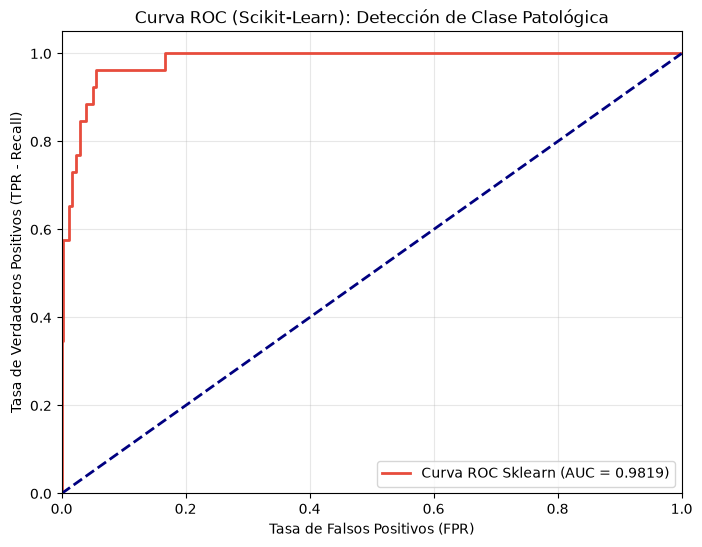

In [9]:
#datos para la Curva ROC de Scikit-Learn (Clase 3 vs Resto)
y_test_roc = np.where(y_test_og == 3, 1, 0)
fpr_sk, tpr_sk, roc_auc_sk = calcular_roc_auc(y_test_roc, probs_test_sk)

#Curva ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr_sk, tpr_sk, color='#e74c3c', lw=2, label=f'Curva ROC Sklearn (AUC = {roc_auc_sk:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR - Recall)')
plt.title('Curva ROC (Scikit-Learn): Detección de Clase Patológica')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()


plt.show()

### Conclusión de la Comparativa (Modelo Propio vs. Scikit-Learn)

Al comparar nuestra Regresión Logística hecha contra la versión de `scikit-learn` bajo el mismo enfoque de triage binario (`threshold=0.3`, entrenando con `learning_rate=0.1` y `n_iterations=2000` sin la clase Sospechosa), observamos que la implementación ofrece practicamente la misma calidad clínica y capacidad de discriminación

* **Detección de riesgos y capacidad discriminativa:** Ambos modelos igualaron exactamente la sensibilidad en la clase crítica, detectando **25 de los 26** fetos en estado Patológico (**96.15%** de Recall), y dividieron los 65 casos Sospechosos de forma idéntica (**44** asignados a Normal y **21** elevados a Patológico). Nuestro modelo obtuvo una ligera ventaja en el área bajo la curva ROC (**0.9825** vs. **0.9819** de AUC), mientras que `scikit-learn` logró una exactitud aparente marginalmente mayor (**84.04%** vs. **83.33%**) al cometer 3 falsos positivos menos en pacientes sanos.


* **Relación tiempo-calidad:** `scikit-learn` entrena más rápido (**0.0184 s** frente a **0.1830 s**) porque utiliza optimizadores compilados, mientras que nuestro código corre en Python puro. Sin embargo, al evaluar pacientes nuevos (predicción en prueba), nuestro modelo responde incluso más rápido (**0.000362 s** vs. **0.000512 s**)